## Grupo 14. Exploración de la matriz de valores de referencia por barrio
### Proyecto: análisis de dinámicas inmobiliarias en Bogotá D. C.
#### Objetivo
Este notebook documenta una primera exploración de la matriz territorial unificada. Buscamos conocer su estructura, evaluar aspectos básicos de calidad, describir la distribución de los valores de referencia para 2015 y 2026, comparar resultados entre localidades y examinar la relación entre ambos periodos.

#### Librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt ## creo que deben instalarlo en sus venv
import seaborn as sns ## creo que deben instalarlo en sus venv

#### Datos - matriz_barrios_unificada.csv

In [2]:
matriz="../data/matriz_barrios_unificada.csv"
df= pd.read_csv(matriz)
display(df.head())

,localidad,barrio,v_ref_2015,v_ref_2025,v_ref_2026,cagr_15_25,num_estaciones_transmilenio,num_listings_airbnb,geometry
0,USME,EL BOSQUE,290000.0,650000.0,660000.0,0.084056,0,0.0,POLYGON ((-74.10014659299998 4.505445796000060...
1,SUBA,BILBAO,750000.0,1790000.0,2050000.0,0.090886,0,0.0,"POLYGON ((-74.113150507 4.751871279999989, -74..."
2,KENNEDY,CIUDAD KENNEDY CENTRAL,1000000.0,2900000.0,2640000.0,0.112346,0,7.0,POLYGON ((-74.15600688799998 4.616521243000022...
3,CHAPINERO,CONCEPCION NORTE,1400000.0,3580000.0,4380000.0,0.098438,1,0.0,POLYGON ((-74.06568096400002 4.656363177999992...
4,PUENTE ARANDA,COLON,1300000.0,2850000.0,3170000.0,0.081658,0,16.0,POLYGON ((-74.11963554699997 4.619638797999983...


In [3]:
print("Dimensiones de la matriz:", df.shape)
print("\nNombres de las columnas:")
print(df.columns.tolist())

Dimensiones de la matriz: (1150, 9)

Nombres de las columnas:
['localidad', 'barrio', 'v_ref_2015', 'v_ref_2025', 'v_ref_2026', 'cagr_15_25', 'num_estaciones_transmilenio', 'num_listings_airbnb', 'geometry']


#### Revisión de la calidad de los datos
Revisamos los tipos de datos, los valores faltantes, las filas exactamente duplicadas y las estadísticas descriptivas. Esta revisión permite detectar problemas que podrían distorsionar las comparaciones o el entrenamiento posterior.

In [4]:
# Tipos de datos
print("Tipos de variables:")
display(df.dtypes.to_frame("tipo"))

# Valores faltantes
faltantes = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2)})

print("Valores faltantes:")
display(faltantes)

# Filas duplicadas
print("Filas duplicadas:", df.duplicated().sum())

# Estadísticas de variables numéricas
print("Estadísticas descriptivas:")
display(df.describe().T)

Tipos de variables:


,tipo
localidad,object
barrio,object
v_ref_2015,float64
v_ref_2025,float64
v_ref_2026,float64
cagr_15_25,float64
num_estaciones_transmilenio,int64
num_listings_airbnb,float64
geometry,object


Valores faltantes:


,cantidad,porcentaje
localidad,0,0.00
barrio,0,0.00
v_ref_2015,47,4.09
v_ref_2025,51,4.43
v_ref_2026,60,5.22
cagr_15_25,0,0.00
num_estaciones_transmilenio,0,0.00
num_listings_airbnb,0,0.00
geometry,0,0.00


Filas duplicadas: 0
Estadísticas descriptivas:


/Users/danielolaurencio/Library/Python/3.9/lib/python/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
v_ref_2015,1103.0,9.037321e+05,8.264273e+05,0.0,250000.000000,8.000000e+05,1.300000e+06,6450000.0
v_ref_2025,1099.0,2.157215e+06,1.571314e+06,0.0,800000.000000,2.150000e+06,3.150000e+06,13525000.0
v_ref_2026,1090.0,2.462160e+06,1.764579e+06,12600.0,950000.000000,2.450000e+06,3.456000e+06,17785000.0
cagr_15_25,1150.0,inf,NaN,-1.0,0.074435,9.595823e-02,1.227829e-01,inf
num_estaciones_transmilenio,1150.0,1.243478e-01,4.121926e-01,0.0,0.000000,0.000000e+00,0.000000e+00,3.0
num_listings_airbnb,1150.0,1.229304e+01,5.068916e+01,0.0,0.000000,0.000000e+00,4.000000e+00,883.0


#### Valores cero, infinitos y claves territoriales
La tasa cagr_15_25 puede contener valores infinitos cuando el valor de referencia inicial es cero y el final es positivo. Por eso, antes de interpretar esa variable, contamos explícitamente los infinitos y los ceros. También revisamos si se repite la combinación localidad–barrio.

Que una combinación de nombres aparezca una sola vez no garantiza que no existan duplicados territoriales: pueden existir nombres similares, variantes de escritura o geometrías que se solapen. Esos casos requieren validación adicional.

In [5]:
# Contar valores infinitos en CAGR
infinitos = np.isinf(df["cagr_15_25"]).sum()
print("Valores infinitos en CAGR:", infinitos)

# Revisar valores de referencia iguales a cero
print("v_ref_2015 iguales a cero:",
      (df["v_ref_2015"] == 0).sum())

print("v_ref_2025 iguales a cero:",
      (df["v_ref_2025"] == 0).sum())

# Revisar valores negativos
print("v_ref_2015 negativos:",
      (df["v_ref_2015"] < 0).sum())

print("v_ref_2025 negativos:",
      (df["v_ref_2025"] < 0).sum())

# Revisar barrios repetidos
print("Registros con localidad y barrio repetidos:",
      df.duplicated(["localidad", "barrio"]).sum())

# Mostrar registros con CAGR infinito
display(
    df.loc[
        np.isinf(df["cagr_15_25"]),
        ["localidad", "barrio", "v_ref_2015",
         "v_ref_2025", "cagr_15_25"]
    ].head(10)
)

Valores infinitos en CAGR: 52
v_ref_2015 iguales a cero: 68
v_ref_2025 iguales a cero: 36
v_ref_2015 negativos: 0
v_ref_2025 negativos: 0
Registros con localidad y barrio repetidos: 0


,localidad,barrio,v_ref_2015,v_ref_2025,cagr_15_25
44,CIUDAD BOLIVAR,PASQUILLA URBANA,0.0,25750.0,inf
45,KENNEDY,LAS ACACIAS RURAL,0.0,13440.0,inf
57,KENNEDY,VEREDA EL TINTAL URBANO,0.0,392274.5,inf
59,SUBA,SANTA CECILIA DE SUBA I,0.0,40100.0,inf
60,SAN CRISTOBAL,AGUAS CLARAS I,0.0,600000.0,inf
75,USME,EL NUEVO PORTAL II RURAL,0.0,127100.0,inf
91,SANTA FE,LA PEÑA I,0.0,151000.0,inf
96,USME,TOCAIMITA ORIENTAL,0.0,127100.0,inf
135,BOSA,BOSA 37,0.0,81000.0,inf
146,BOSA,EL REMANSO,0.0,130100.0,inf


#### Revisión de datos faltantes en los dos periodos
Contamos los registros sin valor para 2015 y para 2026, distinguiendo los que no tienen información en ninguno de los dos años de aquellos que tienen información parcial.

In [9]:
# Registros sin valor en alguno de los años
sin_2015 = df["v_ref_2015"].isna()
sin_2026 = df["v_ref_2026"].isna()

print("Sin valor en 2015:", sin_2015.sum())
print("Sin valor en 2026:", sin_2026.sum())
print("Sin valor en ambos años:", (sin_2015 & sin_2026).sum())
print("Sin valor en al menos un año:",
      (sin_2015 | sin_2026).sum())

# Mostrar algunos casos
display(
    df.loc[
        sin_2015 | sin_2026,
        ["localidad", "barrio", "v_ref_2015", "v_ref_2026"]
    ].head(15)
)

Sin valor en 2015: 47
Sin valor en 2026: 60
Sin valor en ambos años: 47
Sin valor en al menos un año: 60


,localidad,barrio,v_ref_2015,v_ref_2026
39,USME,EL UVAL III,NaN,NaN
55,SUMAPAZ,LAS ANIMAS,NaN,NaN
72,SUMAPAZ,LAS PALMAS,NaN,NaN
87,FONTIBON,EL PANTANO,92344.5,NaN
97,FONTIBON,EL CHANCO RURAL III,NaN,NaN
133,CIUDAD BOLIVAR,QUIBA BAJO V,NaN,NaN
149,CIUDAD BOLIVAR,QUIBA ALTO,NaN,NaN
150,USAQUEN,TORCA III,NaN,NaN
156,SUMAPAZ,LOS ARRAYANES,NaN,NaN
174,TEUSAQUILLO,PARQUE DISTRITAL SALITRE,80000.0,NaN


#### Distribución de los valores de referencia
Los histogramas muestran cómo se distribuyen los valores de cada periodo. Permiten identificar concentración de observaciones, asimetría y posibles valores extremos. Para esta visualización no modificamos los valores originales; simplemente excluimos los faltantes de cada columna.

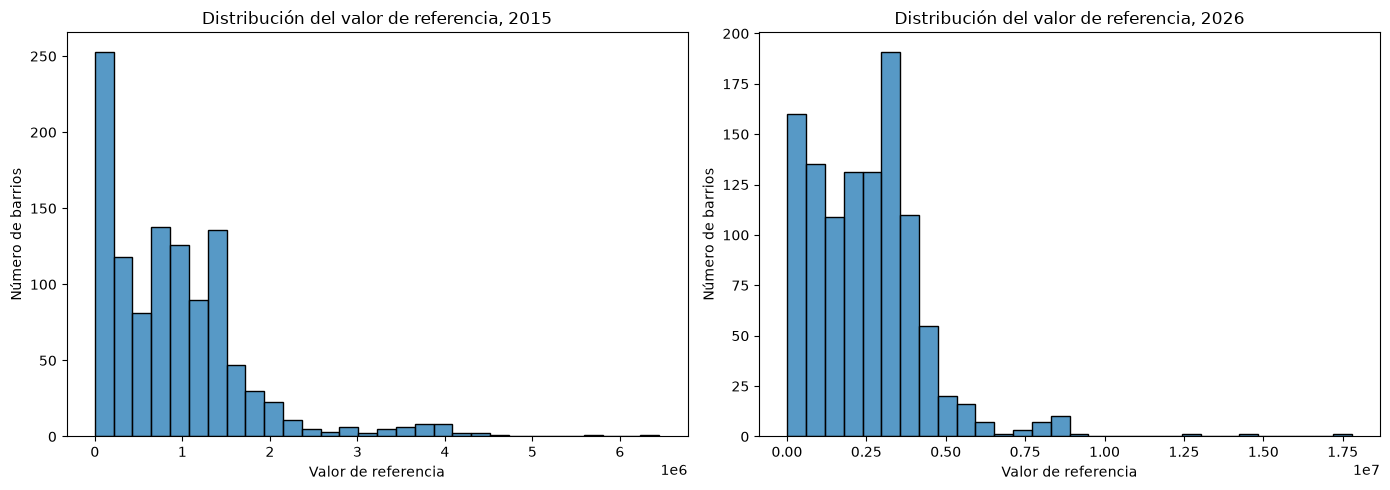

In [10]:
# copia
df_eda = df.copy()

# Excluir infinitos del análisis de crecimiento
df_eda["cagr_15_26"] = df_eda["cagr_15_26"].replace(
    [np.inf, -np.inf], np.nan)

# Gráfico 1. Distribución de valores de referencia
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df_eda["v_ref_2015"].dropna(),
    bins=30, ax=axes[0]
)
axes[0].set_title("Distribución del valor de referencia, 2015")
axes[0].set_xlabel("Valor de referencia")
axes[0].set_ylabel("Número de barrios")

sns.histplot(
    df_eda["v_ref_2026"].dropna(),
    bins=30, ax=axes[1]
)
axes[1].set_title("Distribución del valor de referencia, 2026")
axes[1].set_xlabel("Valor de referencia")
axes[1].set_ylabel("Número de barrios")

plt.tight_layout()
plt.show()

#### Barrios con valores extremos
Ordenamos los registros con valor disponible en 2026 para inspeccionar los diez valores más altos. Este listado ayuda a detectar observaciones que conviene verificar con la fuente original. Un valor extremo no es automáticamente un error: puede corresponder a una característica territorial real o a una diferencia de cobertura/metodología.

In [11]:
# Seleccionar registros con valor disponible en 2026
df_validos = df.dropna(subset=["v_ref_2026"]).copy()

# Ordenar de mayor a menor valor de referencia
mayores_2026 = df_validos.sort_values(
    "v_ref_2026", ascending=False
).head(10)

display(
    mayores_2026[
        ["localidad", "barrio", "v_ref_2015", "v_ref_2026"]
    ])

,localidad,barrio,v_ref_2015,v_ref_2026
897,SANTA FE,SANTA INES,220000.0,17785000.0
825,CHAPINERO,EL RETIRO,5800000.0,14300000.0
499,CHAPINERO,ESCUELA DE INFANTERIA,2000000.0,12500000.0
818,SANTA FE,SAGRADO CORAZON,2121793.0,9100000.0
17,CHAPINERO,CHICO NORTE II SECTOR,4350000.0,8700000.0
310,CHAPINERO,CHICO NORTE,4350000.0,8700000.0
229,CHAPINERO,EL REFUGIO I,1528017.0,8673659.0
452,CHAPINERO,ANTIGUO COUNTRY,3700000.0,8500000.0
468,CHAPINERO,LAGO GAITAN,3400000.0,8472500.0
350,CHAPINERO,PARAMO I RURAL,3002853.5,8450000.0


#### Crecimiento porcentual entre 2015 y 2025
Para comparar el cambio entre periodos calculamos el crecimiento porcentual acumulado únicamente en los registros con valores positivos en ambos años.

Se excluyen los valores iniciales iguales a cero porque la división no está definida. El resultado corresponde al cambio acumulado entre los dos años, no a una tasa anual. Además, los porcentajes pueden ser muy altos cuando el valor inicial es pequeño, por lo que deben revisarse junto con los valores absolutos.

In [7]:
df_crecimiento = df.loc[
    df["v_ref_2015"].gt(0)
    & df["v_ref_2025"].gt(0) & df["cagr_15_25"].gt(0)
].copy()

df_crecimiento["crecimiento_porcentual"] = (
    (df_crecimiento["v_ref_2026"] /
     df_crecimiento["v_ref_2015"] - 1) * 100
)

print("Barrios válidos para comparar:",
      len(df_crecimiento))

display(
    df_crecimiento[
        ["localidad", "barrio",
         "v_ref_2015", "cagr_15_25", "v_ref_2026",
         "crecimiento_porcentual"]
    ].sort_values(
        "crecimiento_porcentual", ascending=False
    ).head(10)
)

Barrios válidos para comparar: 989


,localidad,barrio,v_ref_2015,cagr_15_25,v_ref_2026,crecimiento_porcentual
915,USAQUEN,ESCUELA DE CABALLERIA I,25000.0,0.469824,3332790.5,13231.162000
914,CIUDAD BOLIVAR,ESPINO I,9000.0,0.046657,790000.0,8677.777778
165,CIUDAD BOLIVAR,ESPINO,9000.0,0.046657,790000.0,8677.777778
69,BOSA,SAN BERNARDINO XXV,10000.0,0.402756,643000.0,6330.000000
912,ENGATIVA,PARQUE POPULAR SALITRE,80000.0,0.467274,3910016.0,4787.520000
1026,KENNEDY,EL VERGEL ORIENTAL,75000.0,0.084953,3074472.0,3999.296000
77,BOSA,SAN BERNARDINO XXV URBANO,20000.0,0.284735,800000.0,3900.000000
28,SUBA,SAN PEDRO RURAL,85000.0,0.301029,2550000.0,2900.000000
549,USAQUEN,TIBABITA EL ROSARIO,29439.0,0.318237,855000.0,2804.310608
738,ENGATIVA,EL DORADO RURAL,28000.0,0.402492,727527.0,2498.310714


### Hay duplicados? ESPINO 1 y ESPINO

In [8]:
espinos = df.loc[
    df["barrio"].str.contains("ESPINO", case=False, na=False)
].copy()

for _, fila in espinos.iterrows():
    print("Barrio:", fila["barrio"])
    print("Valor 2015:", fila["v_ref_2015"])
    print("Valor 2026:", fila["v_ref_2026"])
    print("Longitud de geometría:", len(fila["geometry"]))
    print("Geometría completa:", fila["geometry"])
    print("-" * 60)

Barrio: ESPINO
Valor 2015: 9000.0
Valor 2026: 790000.0
Longitud de geometría: 9289
Geometría completa: POLYGON ((-74.171775432 4.586584234999975, -74.17167993499999 4.586407367999982, -74.17167257199998 4.586408865999999, -74.17160740899999 4.58643975199999, -74.171574798 4.586455225000009, -74.17146893400002 4.586505451999983, -74.17146459100002 4.5864975079999795, -74.17140562200001 4.586515420000012, -74.17140477999999 4.586513503999981, -74.17137885099999 4.586454489999994, -74.17136512799999 4.586442061000014, -74.171334161 4.586415649000003, -74.17132522399999 4.586404634000019, -74.17129087900003 4.586368898999979, -74.17119751199999 4.586273989999995, -74.17118273199998 4.586258966000003, -74.17114001300001 4.586215541000001, -74.17113992600002 4.5862154449999935, -74.17112549500001 4.586198287000002, -74.171093192 4.586160502999974, -74.17107415700002 4.586139097, -74.17107391000002 4.586138818999984, -74.17106053600003 4.586123778000001, -74.17105023300002 4.586112110999977, 

Pareciera que tienen geometrias diferentes pero para mi son los mismos

In [9]:
from shapely import wkt

espinos = df.loc[
    df["barrio"].str.contains("ESPINO", case=False, na=False)
].copy()

geom_espino = wkt.loads(
    espinos.loc[espinos["barrio"].str.upper() == "ESPINO",
                "geometry"].iloc[0]
)

geom_espino_i = wkt.loads(
    espinos.loc[espinos["barrio"].str.upper() == "ESPINO I",
                "geometry"].iloc[0]
)

print("¿Geometrías idénticas?:", geom_espino.equals(geom_espino_i))
print("¿Se intersectan?:", geom_espino.intersects(geom_espino_i))
print("¿Se superponen?:", geom_espino.overlaps(geom_espino_i))
print("Área de ESPINO:", geom_espino.area)
print("Área de ESPINO I:", geom_espino_i.area)

¿Geometrías idénticas?: False
¿Se intersectan?: True
¿Se superponen?: False
Área de ESPINO: 1.5911751028580703e-05
Área de ESPINO I: 1.534100700620887e-05


#### Comparar los valores por localidad

In [10]:
# Resumen de valores por localidad
resumen_localidades = (
    df.groupby("localidad")
    .agg(
        barrios=("barrio", "count"),
        valor_mediano_2015=("v_ref_2015", "median"),
        valor_mediano_2026=("v_ref_2026", "median"),
        valor_promedio_2015=("v_ref_2015", "mean"),
        valor_promedio_2026=("v_ref_2026", "mean")
    )
    .sort_values("valor_mediano_2026", ascending=False)
)

display(resumen_localidades.round(2))

,barrios,valor_mediano_2015,valor_mediano_2026,valor_promedio_2015,valor_promedio_2026
localidad,,,,,
CHAPINERO,55,2000000.00,4380000.0,1985434.46,4581615.00
TEUSAQUILLO,30,1500000.00,4200000.0,1472916.67,4215138.62
BARRIOS UNIDOS,24,1500000.00,4030000.0,1601562.50,4079583.33
LOS MARTIRES,8,1175000.00,3602500.0,1396875.00,3553125.00
USAQUEN,89,1400000.00,3500000.0,1603553.78,3182421.49
PUENTE ARANDA,56,1200000.00,3494500.0,1228736.51,3503592.71
ENGATIVA,85,1500000.00,3459000.0,1335198.95,3267273.10
SANTA FE,37,1000000.00,3205000.0,1038556.50,3621263.22
ANTONIO NARIÑO,6,975000.00,3075000.0,1010416.67,3158333.33


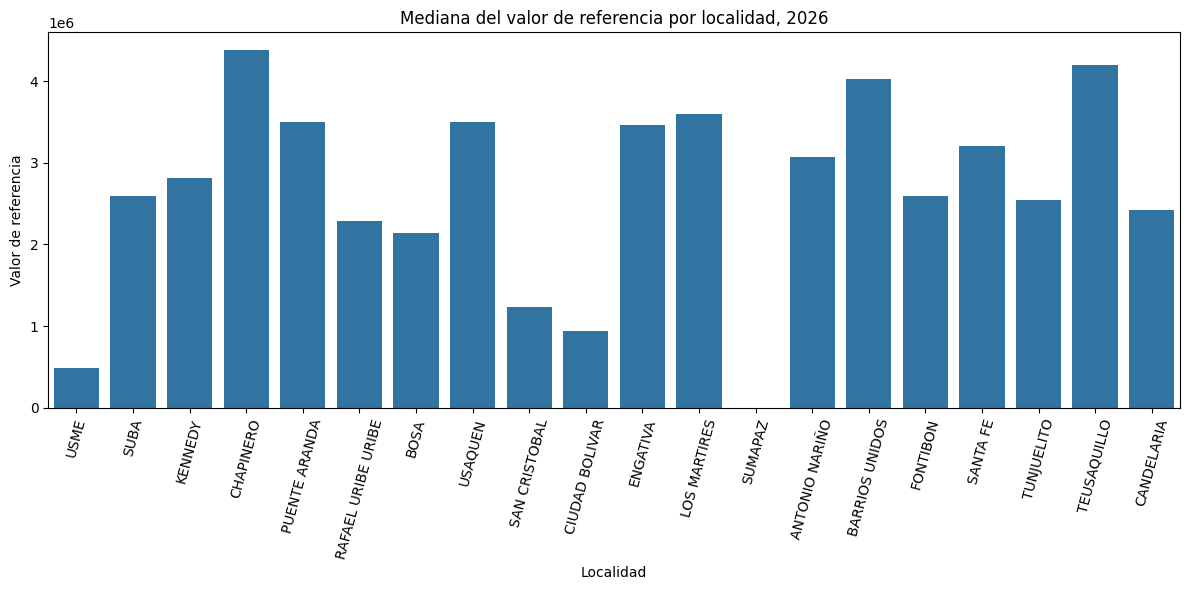

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="localidad",
    y="v_ref_2026",
    estimator="median",
    errorbar=None
)

plt.title("Mediana del valor de referencia por localidad, 2026")
plt.xlabel("Localidad")
plt.ylabel("Valor de referencia")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

El gráfico compara las medianas por localidad. Las diferencias observadas son descriptivas y deben interpretarse teniendo en cuenta la definición de los valores, la cobertura de cada localidad y la cantidad de registros disponibles.

#### Crecimiento por localidad

In [19]:
# Comparar únicamente registros con valores positivos en ambos años
df_crecimiento = df.loc[
    df["v_ref_2015"].gt(0)
    & df["v_ref_2026"].gt(0)
].copy()

# Crecimiento porcentual acumulado por barrio
df_crecimiento["crecimiento_pct"] = (
    df_crecimiento["v_ref_2026"] /
    df_crecimiento["v_ref_2015"] - 1
) * 100

# Resumen por localidad
crecimiento_localidad = (
    df_crecimiento.groupby("localidad")
    .agg(
        barrios_validos=("barrio", "count"),
        mediana_crecimiento=("crecimiento_pct", "median"),
        promedio_crecimiento=("crecimiento_pct", "mean")
    )
    .sort_values("mediana_crecimiento", ascending=False)
)

display(crecimiento_localidad.round(2))

,barrios_validos,mediana_crecimiento,promedio_crecimiento
localidad,,,
CIUDAD BOLIVAR,104,370.00,665.72
SANTA FE,35,232.39,491.90
USME,121,230.00,340.48
RAFAEL URIBE URIBE,58,229.86,236.63
ANTONIO NARIÑO,6,221.88,217.03
TUNJUELITO,5,217.50,238.74
CANDELARIA,2,216.87,216.87
KENNEDY,80,209.29,284.77
LOS MARTIRES,8,199.35,175.47


In [20]:
crecimiento_localidad["barrios_validos"].sum()

np.int64(1027)

#### Relación entre los valores de 2015 y 2026
El diagrama de dispersión permite observar si los barrios con valores de referencia altos en 2015 tienden también a tener valores altos en 2026. Para el gráfico se utilizan únicamente registros con ambos valores disponibles. La relación visual describe asociación, no causalidad.

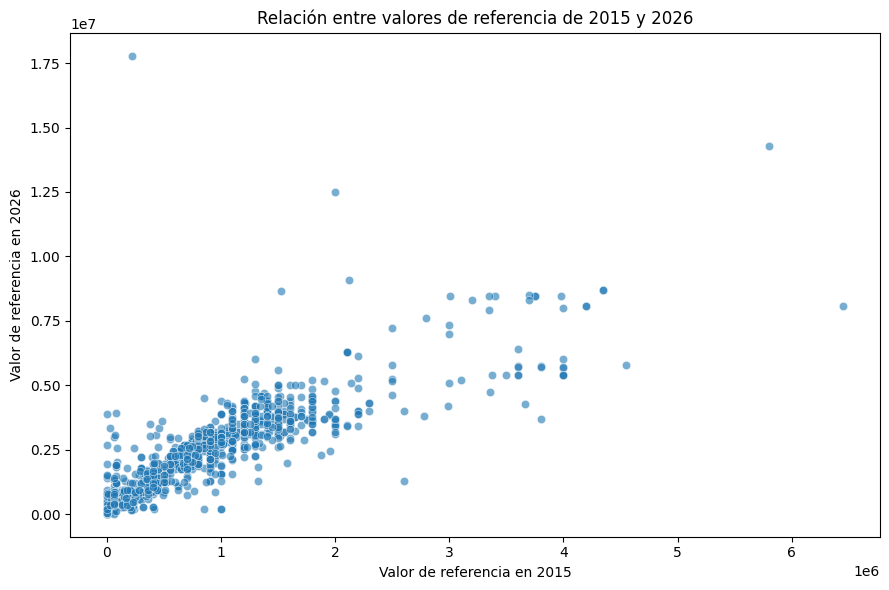

In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="v_ref_2015",
    y="v_ref_2026",
    alpha=0.6
)

plt.title("Relación entre valores de referencia de 2015 y 2026")
plt.xlabel("Valor de referencia en 2015")
plt.ylabel("Valor de referencia en 2026")
plt.tight_layout()
plt.show()

#### Correlaciones de Pearson y Spearman

In [24]:
# Seleccionar registros con ambos valores disponibles
datos_correlacion = df[
    ["v_ref_2015", "v_ref_2026"]
].dropna()

correlacion = datos_correlacion.corr().iloc[0, 1]

print("Registros analizados:", len(datos_correlacion))
print("Correlación de Pearson:", round(correlacion, 4))

Registros analizados: 1090
Correlación de Pearson: 0.8322


In [25]:
spearman = datos_correlacion.corr(method="spearman").iloc[0, 1]

print("Correlación de Spearman:", round(spearman, 4))

Correlación de Spearman: 0.9008


Calculamos dos medidas complementarias. Pearson resume la intensidad de la relación lineal y puede verse afectada por valores extremos. Spearman evalúa si existe una relación monótona a partir del orden de los valores, por lo que resulta útil cuando la relación no es estrictamente lineal.

Las correlaciones se calculan con registros que tienen ambos valores observados. No deben interpretarse como evidencia de que un valor cause el otro ni como una evaluación de desempeño predictivo.

#### Visualización con escala logarítmica
Los valores están concentrados en un rango amplio y existen observaciones extremas. La escala logarítmica permite visualizar mejor los valores pequeños y la estructura general de la nube de puntos. Como el logaritmo no está definido para cero ni para valores negativos, este gráfico incluye exclusivamente registros con valores positivos en ambos años. Los datos originales no se modifican.

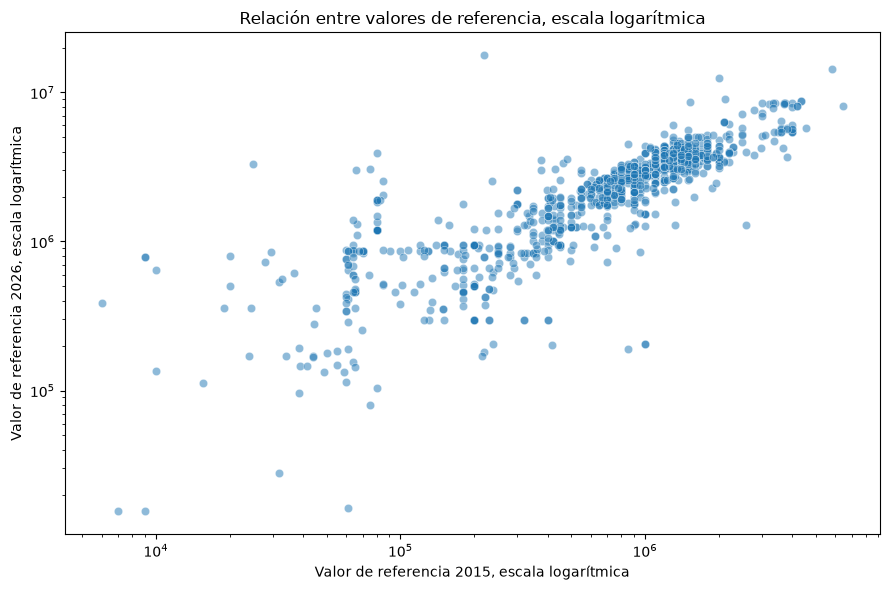

In [26]:
datos_log = datos_correlacion[
    (datos_correlacion["v_ref_2015"] > 0) &
    (datos_correlacion["v_ref_2026"] > 0)
].copy()

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos_log,
    x="v_ref_2015",
    y="v_ref_2026",
    alpha=0.5
)

plt.xscale("log")
plt.yscale("log")

plt.title("Relación entre valores de referencia, escala logarítmica")
plt.xlabel("Valor de referencia 2015, escala logarítmica")
plt.ylabel("Valor de referencia 2026, escala logarítmica")

plt.tight_layout()
plt.show()

#### Relación entre CAGR de 2015 a 2025 y el valor de referencia de 2026

Coeficiente de correlación de Pearson (Sin Outliers ni Infinitos): -0.1626


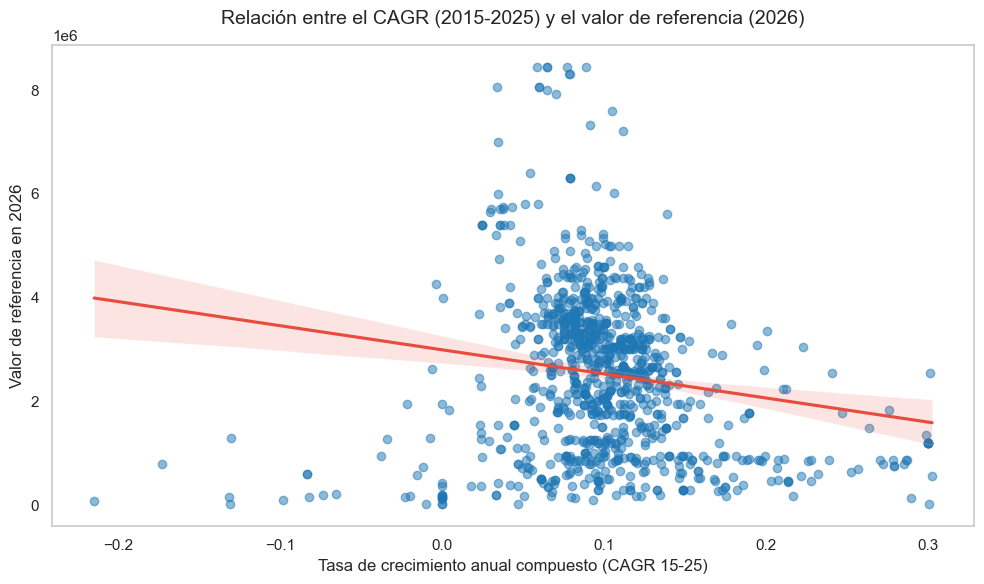

In [34]:


# 1. Limpieza profunda
df_clean = df.copy()

# Convertir infinitos a nulos y eliminarlos
df_clean.replace([np.inf, -np.inf], np.nan, inplace=True)
df_clean = df_clean.dropna(subset=['cagr_15_25', 'v_ref_2026'])

# Descartar los errores de CAGR
df_clean = df_clean[df_clean['cagr_15_25'] > -0.99]

# Filtrar el 1% de valores atípicos más altos para ver la tendencia real
limite_superior_precio = df_clean['v_ref_2026'].quantile(0.99)
limite_superior_cagr = df_clean['cagr_15_25'].quantile(0.99)

df_clean = df_clean[(df_clean['v_ref_2026'] <= limite_superior_precio) & 
                    (df_clean['cagr_15_25'] <= limite_superior_cagr)]

# 2. Recálculo estadístico
correlacion = df_clean[['cagr_15_25', 'v_ref_2026']].corr().iloc[0, 1]
print(f"Coeficiente de correlación de Pearson (Sin Outliers ni Infinitos): {correlacion:.4f}")

# 3. Visualización
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

ax = sns.regplot(
    data=df_clean, 
    x='cagr_15_25', 
    y='v_ref_2026',
    scatter_kws={'alpha':0.5, 'color': "#1f77b4"}, 
    line_kws={'color': '#E74C3C'}
)

plt.title('Relación entre el CAGR (2015-2025) y el valor de referencia (2026)', fontsize=14, pad=15)
plt.xlabel('Tasa de crecimiento anual compuesto (CAGR 15-25)', fontsize=12)
plt.ylabel('Valor de referencia en 2026', fontsize=12)
plt.grid(False)
plt.tight_layout()
plt.show()

#### Relación entre número de estaciones y el valor de referencia

/var/folders/63/cdh2flb14xn_3wgvc3t8vlr00000gn/T/ipykernel_16282/2104631742.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


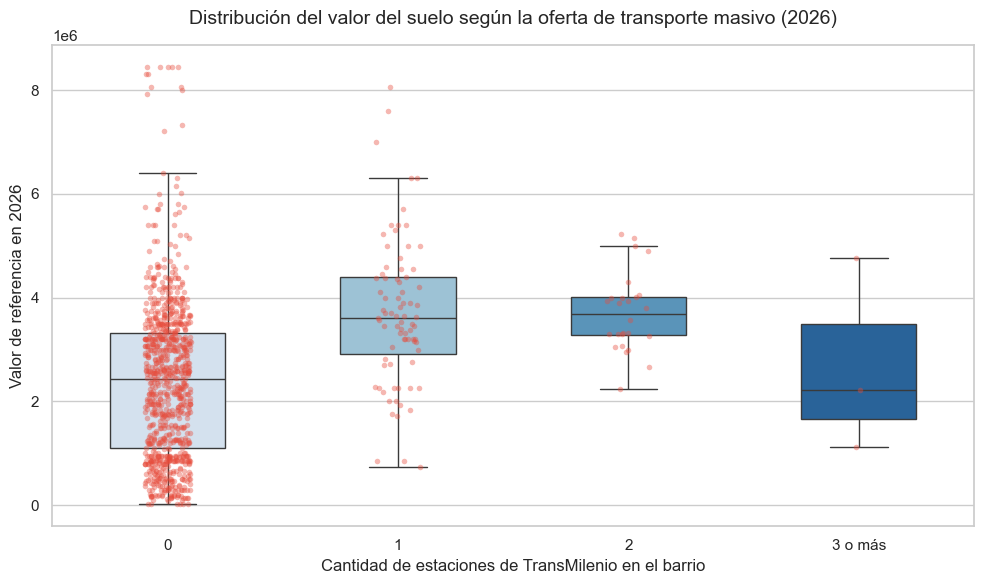

In [30]:
# 1. Preparación de los datos
df_vis = df_clean.copy()

# Agrupar las categorías altas para evitar que la gráfica se distorsione 
# si hay un solo barrio con muchas estaciones (ej. 5 o 6)
df_vis['estaciones_agrupadas'] = df_vis['num_estaciones_transmilenio'].apply(
    lambda x: '3 o más' if x >= 3 else str(int(x))
)

orden = ['0', '1', '2', '3 o más']

# 2. Configuración visual
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Boxplot para la estructura estadística (medianas y cuartiles)
# showfliers=False oculta los puntos atípicos del boxplot para no duplicarlos con el stripplot
sns.boxplot(
    data=df_vis,
    x='estaciones_agrupadas',
    y='v_ref_2026',
    order=orden,
    palette='Blues',
    showfliers=False,
    width=0.5
)

# 4. Stripplot para la densidad real (cada punto es un barrio)
sns.stripplot(
    data=df_vis,
    x='estaciones_agrupadas',
    y='v_ref_2026',
    order=orden,
    color='#E74C3C',
    alpha=0.4,
    jitter=True,
    size=4
)

# 5. Personalización
plt.title('Distribución del valor del suelo según la oferta de transporte masivo (2026)', fontsize=14, pad=15)
plt.xlabel('Cantidad de estaciones de TransMilenio en el barrio', fontsize=12)
plt.ylabel('Valor de referencia en 2026', fontsize=12)

plt.tight_layout()
plt.show()

#### Relación entre número de listings y el valor de referencia

Coeficiente de correlación de Pearson (Sin Outliers extremos): 0.3806


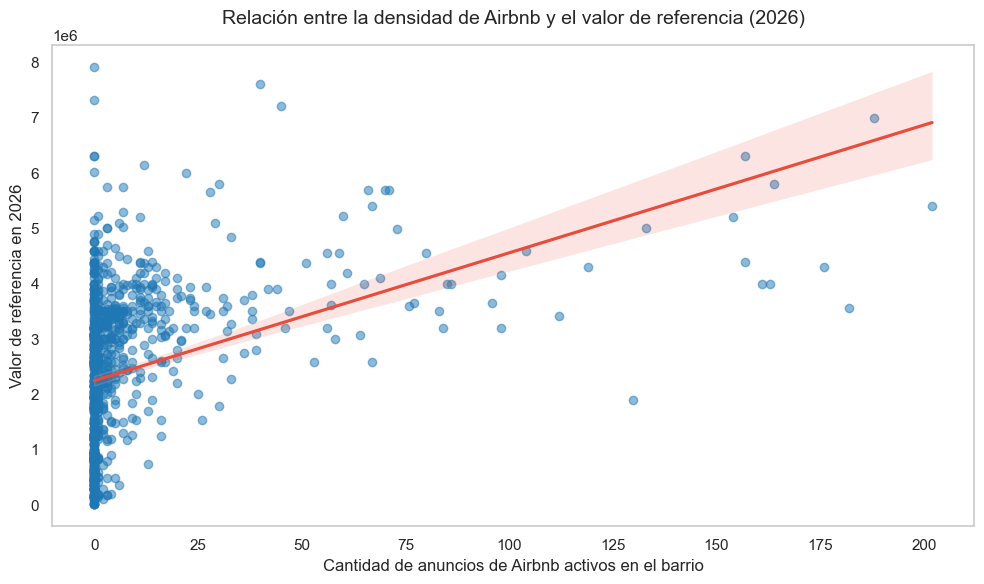

In [35]:

# 1. Preparación y limpieza de datos
df_airbnb = df_clean.copy()

# Eliminar nulos específicos en la columna de Airbnb
df_airbnb = df_airbnb.dropna(subset=['num_listings_airbnb', 'v_ref_2026'])

# Filtrar el 1% de valores atípicos más altos en Airbnb y Precio para ver la tendencia real
limite_superior_precio = df_airbnb['v_ref_2026'].quantile(0.99)
limite_superior_airbnb = df_airbnb['num_listings_airbnb'].quantile(0.99)

df_airbnb = df_airbnb[(df_airbnb['v_ref_2026'] <= limite_superior_precio) & 
                      (df_airbnb['num_listings_airbnb'] <= limite_superior_airbnb)]

# 2. Recálculo estadístico
correlacion_airbnb = df_airbnb[['num_listings_airbnb', 'v_ref_2026']].corr().iloc[0, 1]
print(f"Coeficiente de correlación de Pearson (Sin Outliers extremos): {correlacion_airbnb:.4f}")

# 3. Visualización
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

ax = sns.regplot(
    data=df_airbnb, 
    x='num_listings_airbnb', 
    y='v_ref_2026',
    scatter_kws={'alpha':0.5, 'color': '#1f77b4'}, 
    line_kws={'color': '#E74C3C'}
)

# Personalización del gráfico
plt.title('Relación entre la densidad de Airbnb y el valor de referencia (2026)', fontsize=14, pad=15)
plt.xlabel('Cantidad de anuncios de Airbnb activos en el barrio', fontsize=12)
plt.ylabel('Valor de referencia en 2026', fontsize=12)
plt.grid(False)
plt.tight_layout()
plt.show()

### Conclusiones de la exploración

La matriz contiene 1.150 registros y presenta faltantes en los dos periodos, valores iniciales iguales a cero y tasas de crecimiento infinitas que deben tratarse antes de construir variables para el modelo. Las distribuciones son asimétricas y muestran diferencias entre localidades, así como observaciones de valores elevados que requieren validación con la fuente de origen.

La correlación positiva entre los valores de ambos periodos indica que los barrios con valores de referencia relativamente altos en 2015 suelen mantener valores altos en 2026. Sin embargo, la asociación no demuestra causalidad ni permite concluir que esos barrios hayan experimentado mayor crecimiento porcentual.

Antes de avanzar al modelado se recomienda confirmar la definición y unidad de los valores de referencia, revisar la metodología de agregación territorial y los casos extremos, documentar el tratamiento de faltantes y ceros, y verificar la comparabilidad temporal.